In [ ]:
from sklearn.preprocessing import RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import pickle
from typing import List, Optional, Dict, Tuple
import joblib
import os, re, ast, json, math, random, numpy as np, pandas as pd
import tensorflow as tf
import nibabel as nib
import seaborn as sns
from scipy.ndimage import zoom
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)

In [ ]:
CT_DIR  = Path("/content/drive/MyDrive/Colab Notebooks/ct")
RADIOMICS_DIR = Path("/content/drive/MyDrive/Colab Notebooks/radiomics_ct")

In [ ]:
MANIFEST_CSV = "/content/drive/MyDrive/Colab Notebooks/processed/manifest.csv"
PATIENTS_CSV = "/content/drive/MyDrive/Colab Notebooks/PatientsData.csv"

USE_CROPPED_CT = True
CT_NIFTI_DIR = Path("/content/drive/MyDrive/Colab Notebooks/processed/ct_nifti")
CT_CROPPED_DIR = Path("/content/drive/MyDrive/Colab Notebooks/processed/ct_cropped_nifti")

USE_CROPPED_NPY = False
NPY_CROPPED_DIR = Path("/content/drive/MyDrive/Colab Notebooks/processed/npy_cropped")

TARGET_SHAPE = (128, 128, 128)
BATCH_SIZE = 2
EPOCHS = 25
LR = 1e-4
VAL_SPLIT = 0.2
TEST_SPLIT = 0.1
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE

In [ ]:

PATIENTS_CSV = "/content/drive/MyDrive/Colab Notebooks/PatientsData.csv"

df = pd.read_csv(PATIENTS_CSV, sep=";")
display(df.head(5))

def to_tokens(s):
    if pd.isna(s):
        return []
    s = str(s).upper().replace(" ", "")
    if s in ("", "NONE", "NAN"):
        return []
    return [t for t in s.split(",") if t]

def has_any(token_list, keys):
    return int(any(tok in token_list for tok in keys))

tokens_series = df["Biopsy positive"].apply(to_tokens)

codes = df["Code"].astype(str).str.extract(r"(\d+)")[0]

TTF1 = tokens_series.apply(lambda toks: has_any(toks, {"TTF1"}))
CK7 = tokens_series.apply(lambda toks: has_any(toks, {"CK7"}))

mask_missing = df["Biopsy positive"].isna() | (df["Biopsy positive"].astype(str).str.strip() == "")
TTF1 = TTF1.mask(mask_missing)
CK7 = CK7.mask(mask_missing)


df_labels = pd.DataFrame({
    "Code": codes,
    "TTF1": TTF1.astype("Int64"),
    "CK7": CK7.astype("Int64")
})

display(df_labels.head(10))


print("Distribuție valori TTF1:", df_labels["TTF1"].value_counts(dropna=False).to_dict())
print("Distribuție valori CK7:", df_labels["CK7"].value_counts(dropna=False).to_dict())
print("Număr pacienți cu ambele etichete definite:",
      df_labels.dropna(subset=["TTF1", "CK7"]).shape[0])

print(df_labels)


,Gender,Birthday,Age,Biopsy positive,CT,PET,TYPE,Subtype+ Notes,Code
0,F,21.09.1948,77,"TTF1,NAPSIN A,RP",yes,yes,Adenocarcinoma,(non-mucinous),2011
1,M,26.02.1950,75,"CK AE1/AE3,CEA,CK7,TTF1,KI67",yes,yes,Adenocarcinoma,NaN,3111
2,M,12.11.1956,69,"TTF1,NAPSIN AM",yes,yes,Adenocarcinoma,NaN,4111
3,M,22.12.1961,63,"P63,CK HMW",yes,yes,NSCLC-NOS,NaN,5111
4,F,09.12.1946,78,P63,yes,yes,Squamous cell carcinoma,NaN,7011


,Code,TTF1,CK7
0,2011,1,0
1,3111,1,1
2,4111,1,0
3,5111,0,0
4,7011,0,0
5,8011,1,1
6,9111,0,1
7,10111,1,0
8,11111,1,0
9,12111,1,0


Distribuție valori TTF1: {np.int64(1): 61, np.int64(0): 26}
Distribuție valori CK7: {np.int64(0): 45, np.int64(1): 42}
Număr pacienți cu ambele etichete definite: 87
      Code  TTF1  CK7
0     2011     1    0
1     3111     1    1
2     4111     1    0
3     5111     0    0
4     7011     0    0
..     ...   ...  ...
82  101011     1    1
83  102111     1    0
84  103111     0    0
85  104011     1    0
86  453011     1    1

[87 rows x 3 columns]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
MANIFEST_CSV = "/content/drive/MyDrive/Colab Notebooks/processed/manifest_preproc.csv"
LABELS_CSV = "/content/drive/MyDrive/Colab Notebooks/labels_TTF1_CK7.csv"
RADIOMICS_DIR = Path("/content/drive/MyDrive/Colab Notebooks/radiomics_ct")

PREFERRED_CT_SOURCE = "cropped_nifti"

def _norm_code(x: str) -> str:
    """Extrage doar cifrele din ID (ex: '2011 ' -> '2011')."""
    return pd.Series([x]).astype(str).str.extract(r"(\d+)")[0].iloc[0]

def _pick_ct_path(row, preferred=PREFERRED_CT_SOURCE):
    candidates_order = {
        "cropped_nifti": ["ct_cropped_nifti_path", "ct_nifti_path", "ct_cropped_npy_path", "ct_npy_path"],
        "cropped_npy": ["ct_cropped_npy_path", "ct_npy_path", "ct_cropped_nifti_path", "ct_nifti_path"],
        "nifti": ["ct_nifti_path", "ct_cropped_nifti_path", "ct_npy_path", "ct_cropped_npy_path"],
        "npy": ["ct_npy_path", "ct_cropped_npy_path", "ct_nifti_path", "ct_cropped_nifti_path"],
    }[preferred]

    chosen_col, chosen_path = None, None
    for col in candidates_order:
        if col in row and pd.notna(row[col]) and str(row[col]).strip():
            p = str(row[col]).strip()
            if os.path.exists(p):
                chosen_col, chosen_path = col, p
                break
    return chosen_col, chosen_path

def _build_radiomics_path(code: str) -> str:
    p = RADIOMICS_DIR / f"{code}_radiomics.txt"
    return str(p)

def _exists(p: str) -> bool:
    return (p is not None) and os.path.exists(p)


In [ ]:
def load_labels(labels_csv: str) -> pd.DataFrame:
    df = pd.read_csv(labels_csv, dtype=str)

    for col in ["TTF1", "CK7"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    df["Code"] = df["Code"].astype(str).apply(_norm_code)
    return df

def load_manifest(manifest_csv: str) -> pd.DataFrame:

    m = pd.read_csv(manifest_csv, dtype=str)
    m.columns = [c.strip() for c in m.columns]

    expected_cols = [
        "Code", "ct_nifti_path", "ct_npy_path",
        "ct_cropped_nifti_path", "ct_cropped_npy_path",
        "bbox_start_x", "bbox_start_y", "bbox_start_z",
        "bbox_size_x", "bbox_size_y", "bbox_size_z",
    ]

    if "Code" not in m.columns:
        alt = [c for c in m.columns if c.lower() == "code"]
        if alt:
            m.rename(columns={alt[0]: "Code"}, inplace=True)

    m["Code"] = m["Code"].astype(str).apply(_norm_code)
    return m

labels_df   = load_labels(LABELS_CSV)
manifest_df = load_manifest(MANIFEST_CSV)

print("Labels:", labels_df.shape, "| Manifest:", manifest_df.shape)

Labels: (87, 3) | Manifest: (87, 12)


In [ ]:
def build_data_index(labels: pd.DataFrame, manifest: pd.DataFrame, preferred=PREFERRED_CT_SOURCE) -> pd.DataFrame:

    use_labels = labels.dropna(subset=["TTF1", "CK7"]).copy()
    idx = use_labels.merge(manifest, on="Code", how="left", suffixes=("",""))

    chosen_cols, chosen_paths = [], []
    for _, row in idx.iterrows():
        col, path = _pick_ct_path(row, preferred=preferred)
        chosen_cols.append(col)
        chosen_paths.append(path)

    idx["ct_source_col"] = chosen_cols
    idx["ct_path"] = chosen_paths

    idx["radiomics_path"] = idx["Code"].apply(_build_radiomics_path)

    idx["ct_exists"] = idx["ct_path"].apply(_exists)
    idx["radiomics_exists"] = idx["radiomics_path"].apply(_exists)

    bbox_cols = ["bbox_start_x","bbox_start_y","bbox_start_z","bbox_size_x","bbox_size_y","bbox_size_z"]
    for c in bbox_cols:
        if c in idx.columns:
            idx[c] = pd.to_numeric(idx[c], errors="coerce")

    idx_ok = idx[(idx["ct_exists"]) & (idx["radiomics_exists"])].copy()

    front_cols = ["Code","TTF1","CK7","ct_path","ct_source_col","radiomics_path","ct_exists","radiomics_exists"]
    other_cols = [c for c in idx_ok.columns if c not in front_cols]
    idx_ok = idx_ok[front_cols + other_cols]

    return idx_ok

data_index = build_data_index(labels_df, manifest_df, preferred=PREFERRED_CT_SOURCE)


print(data_index["ct_source_col"].value_counts(dropna=False))

display(data_index.head(10))


ct_source_col
ct_cropped_nifti_path    87
Name: count, dtype: int64


,Code,TTF1,CK7,ct_path,ct_source_col,radiomics_path,ct_exists,radiomics_exists,ct_nifti_path,ct_npy_path,mask_nifti_path,ct_cropped_nifti_path,ct_cropped_npy_path,bbox_start_x,bbox_start_y,bbox_start_z,bbox_size_x,bbox_size_y,bbox_size_z
0,2011,1,0,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,116,155,192,237,180,61
1,3111,1,1,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,199,268,318,282,211,65
2,4111,1,0,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,49,166,138,357,206,78
3,5111,0,0,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,123,190,131,251,199,59
4,7011,0,0,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,189,186,226,220,208,56
5,8011,1,1,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,235,259,299,251,168,66
6,9111,0,1,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,102,141,118,287,197,66
7,10111,1,0,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,118,167,115,287,174,78
8,11111,1,0,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,104,176,113,265,219,74
9,12111,1,0,/cont

In [ ]:
TARGET_SHAPE = (128, 128, 128)
BATCH_SIZE = 2
AUTOTUNE = tf.data.AUTOTUNE
INDEX_CSV = "/content/drive/MyDrive/Colab Notebooks/TTF1_CK7_data_index_ct_radiomics.csv"

def load_index(index_csv: str) -> pd.DataFrame:
    df = pd.read_csv(index_csv)
    df["Code"] = df["Code"].astype(str)
    return df

data_index = load_index(INDEX_CSV)
display(data_index.head(5))


def load_ct_volume(ct_path: str, target_shape=TARGET_SHAPE):
    img = nib.load(ct_path)
    vol = img.get_fdata().astype(np.float32)
    vol = np.nan_to_num(vol)

    p1, p99 = np.percentile(vol, [1, 99])
    if p99 > p1:
        vol = np.clip((vol - p1) / (p99 - p1), 0, 1)
    else:
        vol = (vol - vol.min()) / (vol.max() - vol.min() + 1e-6)

    factors = (
        target_shape[0] / vol.shape[0],
        target_shape[1] / vol.shape[1],
        target_shape[2] / vol.shape[2]
    )
    vol_resized = zoom(vol, factors, order=1)

    vol_resized = vol_resized[..., np.newaxis]
    return vol_resized



def load_radiomics_features(path: str):
    feats = {}
    with open(path, "r") as f:
        for line in f:
            line = line.strip()
            if not line or ":" not in line:
                continue
            k, v = line.split(":", 1)
            k = k.strip()
            v = v.strip()
            try:
                v_clean = v.replace("np.float64(", "").replace(")", "")
                val = float(v_clean)
                if k.startswith("original_"):
                    feats[k] = val
            except Exception:
                continue
    return feats

,Code,TTF1,CK7,ct_path,ct_source_col,radiomics_path,ct_exists,radiomics_exists,ct_nifti_path,ct_npy_path,mask_nifti_path,ct_cropped_nifti_path,ct_cropped_npy_path,bbox_start_x,bbox_start_y,bbox_start_z,bbox_size_x,bbox_size_y,bbox_size_z
0,2011,1,0,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,116,155,192,237,180,61
1,3111,1,1,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,199,268,318,282,211,65
2,4111,1,0,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,49,166,138,357,206,78
3,5111,0,0,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,123,190,131,251,199,59
4,7011,0,0,/content/drive/MyDrive/Colab Notebooks/process...,ct_cropped_nifti_path,/content/drive/MyDrive/Colab Notebooks/radiomi...,True,True,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,/content/drive/MyDrive/Colab Notebooks/process...,189,186,226,220,208,56


In [ ]:
def build_radiomics_matrix(df: pd.DataFrame):
    rows = []
    for _, row in df.iterrows():
        feats = load_radiomics_features(row["radiomics_path"])
        feats["Code"] = row["Code"]
        rows.append(feats)
    r_df = pd.DataFrame(rows).fillna(0.0)
    return r_df


radiomics_df = build_radiomics_matrix(data_index)
display(radiomics_df.head(5))

,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_Maximum3DDiameter,original_shape_MeshVolume,original_shape_MinorAxisLength,...,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength,Code
0,0.779764,0.595793,152.530083,256.011877,276.193698,228.954491,233.925202,281.726390,2.565493e+06,199.628826,...,9.259426e-12,1.0,0.000003,2.058346e+09,0.0,1000000.0,0.0,0.0,0.0,2011
1,0.640112,0.586923,171.891225,292.868560,287.321700,244.669897,275.697298,287.813411,3.180012e+06,187.468622,...,5.710122e-12,1.0,0.000002,4.005624e+07,0.0,1000000.0,0.0,0.0,0.0,3111
2,0.755895,0.531086,171.433753,322.798641,382.922654,286.714140,338.740314,388.095296,5.550714e+06,244.001770,...,5.169792e-05,2.0,0.000003,3.971136e+11,0.0,1000000.0,0.0,0.0,0.0,4111
3,0.608135,0.578971,163.055600,281.630069,262.377589,212.843696,240.831892,274.271761,2.798453e+06,171.269007,...,7.403367e-12,1.0,0.000003,2.007464e+08,0.0,1000000.0,0.0,0.0,0.0,5111
4,0.732797,0.626018,154.585661,246.934857,233.918019,218.986848,228.973798,268.111990,2.421955e+06,180.953058,...,1.054923e-11,1.0,0.000003,2.358462e+09,0.0,1000000.0,0.0,0.0,0.0,7011


In [ ]:
merged = data_index.merge(radiomics_df, on="Code", how="left")
X_radio = merged[[c for c in merged.columns if c.startswith("original_")]].astype(np.float32).values

scaler = StandardScaler()
X_radio = scaler.fit_transform(X_radio).astype(np.float32)

y = merged[["TTF1", "CK7"]].astype(np.float32).values
ct_paths = merged["ct_path"].tolist()
codes = merged["Code"].tolist()

print("Patients number:", len(codes))
print("Vectors dimensions:", X_radio.shape[1])

Patients number: 87
Vectors dimensions: 107


In [ ]:
def generator(ct_paths, X_radio, y):
    for i in range(len(ct_paths)):
        vol = load_ct_volume(ct_paths[i])
        radio = X_radio[i]
        label = y[i]
        yield (vol, radio), label

output_signature = (
    (tf.TensorSpec(shape=TARGET_SHAPE+(1,), dtype=tf.float32),
     tf.TensorSpec(shape=(X_radio.shape[1],), dtype=tf.float32)),
    tf.TensorSpec(shape=(2,), dtype=tf.float32)
)

dataset = tf.data.Dataset.from_generator(
    lambda: generator(ct_paths, X_radio, y),
    output_signature=output_signature
)

dataset = dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

for (vol, radio), label in dataset.take(1):
    print("Volum batch shape:", vol.shape)
    print("Radiomics batch shape:", radio.shape)
    print("Label batch shape:", label.shape)

Volum batch shape: (2, 128, 128, 128, 1)
Radiomics batch shape: (2, 107)
Label batch shape: (2, 2)


In [ ]:
TARGET_SHAPE = (128, 128, 128)
BATCH_SIZE = 2
EPOCHS = 25
LR = 1e-4
VAL_SPLIT = 0.2
TEST_SPLIT = 0.1
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE
MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_ct_radiomics_SMALL.keras"
SCALER_PATH = "/content/drive/MyDrive/Colab Notebooks/radiomics_scaler.pkl"

In [ ]:
if 'scaler' in globals():
    with open(SCALER_PATH, "wb") as f:
        pickle.dump(scaler, f)
    print("Radiomics scaler saved at:", SCALER_PATH)

Radiomics scaler saved at: /content/drive/MyDrive/Colab Notebooks/radiomics_scaler.pkl


In [ ]:
def get_subset_by_ids(df, ids, ct_paths, X_radio, y):
    """Return the subset of samples (paths, radiomics, labels) for the given patient IDs."""
    df_ids = df[df["Code"].isin(ids)]
    idxs = df.index[df["Code"].isin(ids)].tolist()
    subset_ct_paths = [ct_paths[i] for i in idxs]
    subset_X_radio = X_radio[idxs]
    subset_y = y[idxs]
    return subset_ct_paths, subset_X_radio, subset_y

In [ ]:
def sample_generator(ct_paths, X_radio, y):
    for i in range(len(ct_paths)):
        vol = load_ct_volume(ct_paths[i])
        radio = X_radio[i].astype(np.float32)
        ttf1 = np.float32(y[i][0])
        ck7 = np.float32(y[i][1])
        yield (vol, radio), {"TTF1": ttf1, "CK7": ck7}

In [ ]:
def make_dataset(ct_paths, X_radio, y, batch_size, shuffle=False):
    output_signature = (
        (
            tf.TensorSpec(shape=TARGET_SHAPE+(1,), dtype=tf.float32),
            tf.TensorSpec(shape=(X_radio.shape[1],), dtype=tf.float32),
        ),
        {
            "TTF1": tf.TensorSpec(shape=(), dtype=tf.float32),
            "CK7": tf.TensorSpec(shape=(), dtype=tf.float32),
        }
    )

    ds = tf.data.Dataset.from_generator(
        lambda: sample_generator(ct_paths, X_radio, y),
        output_signature=output_signature
    )
    if shuffle:
        ds = ds.shuffle(buffer_size=min(256, len(ct_paths)))
    def expand_targets(inputs, targets):
        return inputs, {
            "TTF1": tf.expand_dims(targets["TTF1"], -1),
            "CK7": tf.expand_dims(targets["CK7"], -1)
        }
    ds = ds.map(expand_targets, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds

In [ ]:
def prepare_stratified_datasets(data_index, ct_paths, X_radio, y, val_split=0.15, test_split=0.15):
    df_temp = data_index.copy()
    df_temp['stratify_key'] = df_temp['TTF1'].astype(float).astype(str) + "_" + df_temp['CK7'].astype(float).astype(str)

    print(f"--- TOTAL PACIENTI DISPONIBILI: {len(df_temp)} ---")
    print(df_temp['stratify_key'].value_counts().sort_index())
    print("-" * 40)

    remainder_size = val_split + test_split

    try:
        train_df, remainder_df = train_test_split(
            df_temp,
            test_size=remainder_size,
            stratify=df_temp['stratify_key'],
            random_state=42
        )
    except ValueError as e:
        print(f"EROARE la Stratificare (prea putine date pentru o clasa): {e}")
        return None, None, None

    val_relative_size = val_split / remainder_size

    try:
        val_df, test_df = train_test_split(
            remainder_df,
            test_size=(1 - val_relative_size),
            stratify=remainder_df['stratify_key'],
            random_state=42
        )
    except ValueError as e:
        print(f"EROARE la split-ul Val/Test: {e}")
        return None, None, None

    print("\n=== RAPORT DISTRIBUTIE DUPA SPLIT ===")

    datasets = [("TRAIN", train_df), ("VALIDATION", val_df), ("TEST", test_df)]

    for name, df in datasets:
        print(f"\nSet: {name} (Total: {len(df)})")
        counts = df['stratify_key'].value_counts().sort_index()

        for key, count in counts.items():
            parts = key.split('_')
            ttf1_val = parts[0]
            ck7_val = parts[1]
            print(f"  -> TTF1: {ttf1_val} | CK7: {ck7_val} : {count} pacienti")

    print("\n=====================================\n")

    train_ids = train_df['Code'].values
    val_ids = val_df['Code'].values
    test_ids = test_df['Code'].values

    ct_train, radio_train, y_train = get_subset_by_ids(data_index, train_ids, ct_paths, X_radio, y)
    ct_val, radio_val, y_val = get_subset_by_ids(data_index, val_ids, ct_paths, X_radio, y)
    ct_test, radio_test, y_test = get_subset_by_ids(data_index, test_ids, ct_paths, X_radio, y)

    train_ds = make_dataset(ct_train, radio_train, y_train, BATCH_SIZE, shuffle=True)
    val_ds = make_dataset(ct_val, radio_val, y_val, BATCH_SIZE, shuffle=False)
    test_ds = make_dataset(ct_test, radio_test, y_test, BATCH_SIZE, shuffle=False)

    return train_ds, val_ds, test_ds

In [ ]:
train_ds, val_ds, test_ds = prepare_stratified_datasets(
    data_index,
    ct_paths,
    X_radio,
    y,
    val_split=0.10,
    test_split=0.10
)


--- TOTAL PACIENTI DISPONIBILI: 87 ---
stratify_key
0.0_0.0    14
0.0_1.0    12
1.0_0.0    31
1.0_1.0    30
Name: count, dtype: int64
----------------------------------------

=== RAPORT DISTRIBUTIE DUPA SPLIT ===

Set: TRAIN (Total: 69)
  -> TTF1: 0.0 | CK7: 0.0 : 11 pacienti
  -> TTF1: 0.0 | CK7: 1.0 : 9 pacienti
  -> TTF1: 1.0 | CK7: 0.0 : 25 pacienti
  -> TTF1: 1.0 | CK7: 1.0 : 24 pacienti

Set: VALIDATION (Total: 9)
  -> TTF1: 0.0 | CK7: 0.0 : 1 pacienti
  -> TTF1: 0.0 | CK7: 1.0 : 2 pacienti
  -> TTF1: 1.0 | CK7: 0.0 : 3 pacienti
  -> TTF1: 1.0 | CK7: 1.0 : 3 pacienti

Set: TEST (Total: 9)
  -> TTF1: 0.0 | CK7: 0.0 : 2 pacienti
  -> TTF1: 0.0 | CK7: 1.0 : 1 pacienti
  -> TTF1: 1.0 | CK7: 0.0 : 3 pacienti
  -> TTF1: 1.0 | CK7: 1.0 : 3 pacienti




In [ ]:
MODEL_PATH = "/content/drive/MyDrive/Colab Notebooks/model_ct_radiomics_SMALL.keras"

In [ ]:
!pip install tensorflow

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers

def build_small_biomarker_model(input_shape_ct, input_shape_radio):
    reg_l2 = regularizers.l2(0.02)

    input_ct = layers.Input(shape=input_shape_ct, name="input_ct")

    x = input_ct

    x = layers.Conv3D(16, kernel_size=(3, 3, 3), padding='same', kernel_regularizer=reg_l2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling3D(pool_size=(2, 2, 2))(x)

    x = layers.Conv3D(32, kernel_size=(3, 3, 3), padding='same', kernel_regularizer=reg_l2)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.MaxPooling3D(pool_size=(2, 2, 2))(x)

    cnn_features = layers.GlobalAveragePooling3D()(x)
    cnn_features = layers.Dropout(0.5)(cnn_features)

    input_radio = layers.Input(shape=input_shape_radio, name="input_radio")

    y = layers.Dense(16, kernel_regularizer=reg_l2)(input_radio)
    y = layers.BatchNormalization()(y)
    y = layers.Activation('relu')(y)
    y = layers.Dropout(0.4)(y)
    radio_features = y

    combined = layers.Concatenate()([cnn_features, radio_features])

    z = layers.Dense(16, activation='relu', kernel_regularizer=reg_l2)(combined)
    z = layers.Dropout(0.5)(z)

    output_ttf1 = layers.Dense(1, activation='sigmoid', name="TTF1")(z)
    output_ck7 = layers.Dense(1, activation='sigmoid', name="CK7")(z)

    model = models.Model(inputs=[input_ct, input_radio], outputs={"TTF1": output_ttf1, "CK7": output_ck7})
    return model

In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight

def get_weight_values(dataset):
    y_ttf1_all = []
    y_ck7_all = []

    for _, targets in dataset.unbatch():
        y_ttf1_all.append(targets["TTF1"].numpy().item())
        y_ck7_all.append(targets["CK7"].numpy().item())

    # TTF1
    classes_ttf1 = np.unique(y_ttf1_all)
    weights_ttf1 = compute_class_weight(class_weight='balanced', classes=classes_ttf1, y=y_ttf1_all)
    w_ttf1_neg = float(weights_ttf1[0])
    w_ttf1_pos = float(weights_ttf1[1])

    # CK7
    classes_ck7 = np.unique(y_ck7_all)
    weights_ck7 = compute_class_weight(class_weight='balanced', classes=classes_ck7, y=y_ck7_all)
    w_ck7_neg = float(weights_ck7[0])
    w_ck7_pos = float(weights_ck7[1])

    print(f"Ponderi calculate TTF1 -> (0): {w_ttf1_neg:.4f}, (1): {w_ttf1_pos:.4f}")
    print(f"Ponderi calculate CK7 -> (0): {w_ck7_neg:.4f}, (1): {w_ck7_pos:.4f}")

    return w_ttf1_neg, w_ttf1_pos, w_ck7_neg, w_ck7_pos

w_ttf1_0, w_ttf1_1, w_ck7_0, w_ck7_1 = get_weight_values(train_ds)

def add_sample_weights(inputs, targets):
    label_ttf1 = targets["TTF1"]
    label_ck7 = targets["CK7"]

    weight_ttf1 = label_ttf1 * w_ttf1_1 + (1.0 - label_ttf1) * w_ttf1_0
    weight_ck7  = label_ck7  * w_ck7_1  + (1.0 - label_ck7)  * w_ck7_0

    sample_weights = {
        "TTF1": weight_ttf1,
        "CK7": weight_ck7
    }

    return inputs, targets, sample_weights

train_ds_weighted = train_ds.map(add_sample_weights)


Ponderi calculate TTF1 -> (0): 1.7250, (1): 0.7041
Ponderi calculate CK7 -> (0): 0.9583, (1): 1.0455


In [ ]:
import tensorflow as tf
from tensorflow.keras import callbacks, optimizers

tf.keras.backend.clear_session()

ct_shape = TARGET_SHAPE + (1,)
radio_shape = (X_radio.shape[1],)
model = build_small_biomarker_model(ct_shape, radio_shape)

model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-4),
    loss={"TTF1": "binary_crossentropy", "CK7": "binary_crossentropy"},
    metrics={"TTF1": "accuracy", "CK7": "accuracy"}
)

callbacks_list = [
    callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, verbose=1)
]

print("\n--- START TRAINING ---")
history = model.fit(
    train_ds_weighted,
    validation_data=val_ds,
    epochs=100,
    callbacks=callbacks_list,
    verbose=1
)


--- START TRAINING ---
Epoch 1/100
     35/Unknown 41s 220ms/step - CK7_accuracy: 0.5736 - CK7_loss: 0.6431 - TTF1_accuracy: 0.5213 - TTF1_loss: 0.9291 - loss: 3.0802

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


35/35 ━━━━━━━━━━━━━━━━━━━━ 63s 881ms/step - CK7_accuracy: 0.5730 - CK7_loss: 0.6455 - TTF1_accuracy: 0.5205 - TTF1_loss: 0.9274 - loss: 3.0806 - val_CK7_accuracy: 0.5556 - val_CK7_loss: 0.6732 - val_TTF1_accuracy: 0.6667 - val_TTF1_loss: 0.7083 - val_loss: 2.8371 - learning_rate: 1.0000e-04
Epoch 2/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 26s 128ms/step - CK7_accuracy: 0.5638 - CK7_loss: 0.6995 - TTF1_accuracy: 0.5056 - TTF1_loss: 0.7931 - loss: 2.9702 - val_CK7_accuracy: 0.4444 - val_CK7_loss: 0.6945 - val_TTF1_accuracy: 0.5556 - val_TTF1_loss: 0.7106 - val_loss: 2.8275 - learning_rate: 1.0000e-04
Epoch 3/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 25s 121ms/step - CK7_accuracy: 0.5640 - CK7_loss: 0.7769 - TTF1_accuracy: 0.4320 - TTF1_loss: 0.8583 - loss: 3.0859 - val_CK7_accuracy: 0.5556 - val_CK7_loss: 0.7034 - val_TTF1_accuracy: 0.6667 - val_TTF1_loss: 0.7017 - val_loss: 2.8013 - learning_rate: 1.0000e-04
Epoch 4/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 26s 122ms/step - CK7_accuracy: 0.3993 - CK7_loss: 0.9731 - TT

5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 593ms/step
----------------------------------------

REsults for: TTF1
Accuracy : 0.5556
Precision : 0.6250
Recall : 0.8333
F1-Score: 0.7143


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


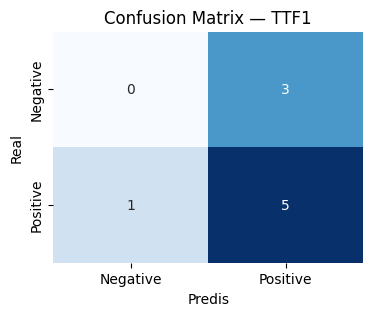

----------------------------------------

REsults for: CK7
Accuracy : 0.5556
Precision : 0.0000
Recall : 0.0000
F1-Score: 0.0000


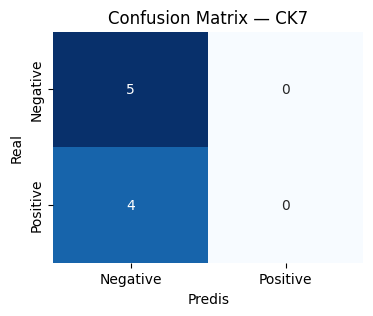

In [ ]:
def plot_confusion_matrix(y_true, y_pred, name):
    cm = confusion_matrix(y_true, y_pred)
    labels = ["Negative", "Positive"]
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels)
    plt.title(f"Confusion Matrix — {name}")
    plt.ylabel("Real")
    plt.xlabel("Predis")
    plt.show()

def print_metrics(y_true, y_pred, name):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    print(f"\nREsults for: {name}")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision : {prec:.4f}")
    print(f"Recall : {rec:.4f}")
    print(f"F1-Score: {f1:.4f}")
    plot_confusion_matrix(y_true, y_pred, name)

y_true_ttf1, y_true_ck7 = [], []
for inputs, targets in test_ds.unbatch():
    y_true_ttf1.append(targets["TTF1"].numpy())
    y_true_ck7.append(targets["CK7"].numpy())

y_true_ttf1 = np.array(y_true_ttf1).astype(int)
y_true_ck7 = np.array(y_true_ck7).astype(int)

preds = model.predict(test_ds)

THRESH = 0.5
y_pred_ttf1 = (preds["TTF1"].ravel() >= 0.45).astype(int)
y_pred_ck7 = (preds["CK7"].ravel() >= 0.58).astype(int)

print("-" * 40)
print_metrics(y_true_ttf1, y_pred_ttf1, "TTF1")
print("-" * 40)
print_metrics(y_true_ck7, y_pred_ck7, "CK7")